# <center> **Proyecto visión por computador:** CNN Segmenter (línea base) </center>

**Por:** María José Bernal, Alejandro Olivares, Santiago Zapata y Jerly Alejandra Galeano

Este notebook entrena y evalúa el modelo **CNN Segmenter (línea base)** con el protocolo común del proyecto, para que su resultado sea comparable con el de los demás modelos.

**Qué pone a prueba.** Es la línea base del proyecto, sin puentes ni preentrenamiento. Sirve de referencia para medir cuánto aportan los puentes y la transferencia de aprendizaje en los demás modelos.

| Elemento | Valor |
|---|---|
| Tamaño de entrada | 350x525 con relleno negro hasta 352x544 |
| Partición | 80/10/10 estratificada (`splits/split.csv`), 4438 / 553 / 555 imágenes |
| Salida | 4 máscaras, una por clase, con sigmoide independiente |
| Pérdida | Focal (γ = 2) + Dice |
| Optimización | AdamW + OneCycleLR, 12 épocas, lote de 16, precisión mixta |
| Selección de la época | Mejor Dice global en validación, con umbral 0.5 |
| Posprocesado | Umbral, área mínima y morfología, calibrados en validación |
| Evaluación | Una sola vez en prueba, sobre 350x525 sin el relleno |

## 1. Configuración
`ENTRENAR = True` entrena el modelo desde cero. Con `ENTRENAR = False` el notebook no entrena y usa los pesos ya guardados en `artifacts/`, para repetir la evaluación o las gráficas sin volver a entrenar.

In [1]:
import sys
import time
import warnings
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")
%config InlineBackend.figure_formats = ["jpeg"]
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import IN_H, IN_W, LABELS, MEAN, METRICA_PRINCIPAL, PROTOCOLO, STD, carpeta_modelo
from datos import CloudDataset, preparar_datos
from entrenamiento import (FocalDice, cargar_pesos, crear_loaders, crear_optimizacion, dispositivo,
                           estado_cpu, fijar_semilla, guardar_pesos, validar)
from evaluacion import evaluar_variantes, guardar_resultados, predecir, tiempo_cpu_ms
from metricas import dice_por_imagen, tabla
from posproceso import aplicar, calibrar
import graficas

MODELO = "cnn"
CARPETA = carpeta_modelo(MODELO)
ENTRENAR = True

fijar_semilla()
device = dispositivo()
print(f"Dispositivo: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))
print(f"Métrica principal: {METRICA_PRINCIPAL}")
print(f"Protocolo: {PROTOCOLO}")
print(f"Artefactos en: {CARPETA}")

Dispositivo: cuda (Tesla T4)
Métrica principal: dice
Protocolo: {'epocas': 12, 'lote': 16, 'lr_max': 0.001, 'weight_decay': 0.0001, 'gamma_focal': 2.0, 'clip_gradiente': 1.0, 'workers': 2}
Artefactos en: /kaggle/working/repo/artifacts/cnn


## 2. Datos
La preparación reduce las 5546 imágenes a 350x525, les agrega el relleno negro hasta 352x544, convierte cada RLE en una máscara de 4 canales y asigna cada imagen a su partición según `splits/split.csv`. Se hace una sola vez por sesión. Si los datos ya están preparados, solo se leen.

In [2]:
indice = preparar_datos()
train_dl, val_dl = crear_loaders()
print(f"Lotes por época: {len(train_dl)} de entrenamiento y {len(val_dl)} de validación")

Datos ya preparados en /kaggle/temp/prep
split
train    4438
test      555
val       553
Lotes por época: 277 de entrenamiento y 18 de validación


### 2.1. Ejemplos de entrenamiento con aumento de datos
Flips, transformación afín suave y cambios leves de brillo y contraste, aplicados igual a la imagen y a sus máscaras.

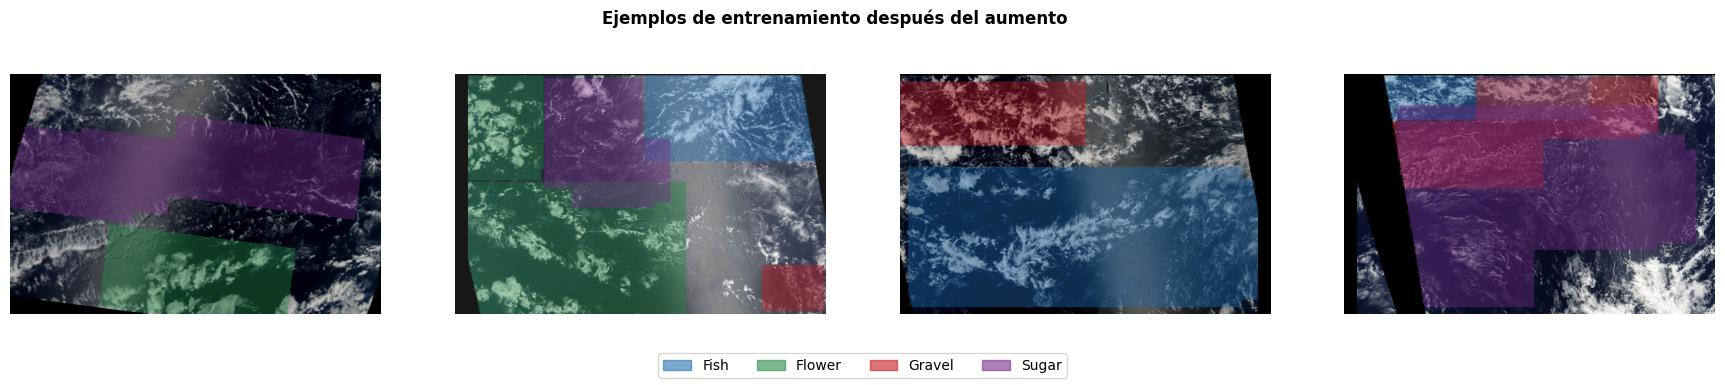

In [3]:
x, y = next(iter(train_dl))
fig, axes = plt.subplots(1, 4, figsize=(22, 3.8))
for ax, img, mask in zip(axes, x[:4], y[:4]):
    img = (np.clip(img.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1) * 255).astype(np.uint8)
    ax.imshow(graficas.superponer(img, mask.numpy() > 0.5))
    ax.axis("off")
graficas.leyenda(fig)
fig.suptitle("Ejemplos de entrenamiento después del aumento", fontweight="bold")
plt.show()

## 3. Implementación del modelo
Encoder-decoder convolucional de cuatro niveles, entrenado desde cero (7.0 M de parámetros).

- **Encoder.** Cada nivel aplica dos convoluciones 3x3 con BatchNorm y ReLU y reduce la resolución a la mitad con max pooling. La imagen pasa de 352x544 a 22x34 en el cuello de botella, con 512 canales.
- **Decoder.** Recupera la resolución con convoluciones transpuestas de paso 2 y otro bloque de dos convoluciones por nivel.
- **Sin puentes (skip connections).** El decoder solo recibe la información comprimida del cuello de botella, así que el detalle espacial debe reconstruirse desde ahí. Es la diferencia clave frente a una U-Net.
- **Regularización.** Dropout espacial que crece con la profundidad (de 0.05 a 0.20).
- **Salida.** Una convolución 1x1 con 4 canales, uno por clase. La sigmoide se aplica fuera del modelo.

La celda siguiente define el modelo y lo guarda en `src/arquitecturas/cnn.py`, para que el notebook del campeón y la app usen exactamente la misma implementación.

In [4]:
%%writefile {ROOT}/src/arquitecturas/cnn.py
import torch.nn as nn


class ConvBlock(nn.Module):
    """Dos convoluciones 3x3 con BatchNorm y ReLU, y Dropout espacial al final."""

    def __init__(self, c_in, c_out, drop):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(c_in, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Conv2d(c_out, c_out, 3, padding=1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True),
            nn.Dropout2d(drop),
        )

    def forward(self, x):
        return self.block(x)


class CNNSegmenter(nn.Module):
    """Encoder-decoder de 4 niveles SIN puentes (skip connections), entrenado desde cero."""

    def __init__(self, classes=4, chans=(32, 64, 128, 256), bottleneck=512):
        super().__init__()
        drops = (0.05, 0.10, 0.15, 0.20)
        enc, c_in = [], 3
        for c, d in zip(chans, drops):
            enc += [ConvBlock(c_in, c, d), nn.MaxPool2d(2)]
            c_in = c
        self.encoder = nn.Sequential(*enc)
        self.bottleneck = ConvBlock(c_in, bottleneck, 0.20)
        dec, c_in = [], bottleneck
        for c, d in zip(reversed(chans), reversed(drops)):
            dec += [nn.ConvTranspose2d(c_in, c, 2, stride=2), ConvBlock(c, c, d)]
            c_in = c
        self.decoder = nn.Sequential(*dec)
        self.head = nn.Conv2d(c_in, classes, 1)

    def forward(self, x):
        return self.head(self.decoder(self.bottleneck(self.encoder(x))))


def construir_modelo(preentrenado=True):
    return CNNSegmenter()

Overwriting /kaggle/working/repo/src/arquitecturas/cnn.py


In [5]:
import arquitecturas.cnn as arquitectura
importlib.reload(arquitectura)

modelo = arquitectura.construir_modelo(preentrenado=False).to(device)
n_params = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
modelo.eval()
with torch.no_grad():
    salida = modelo(torch.zeros(1, 3, 352, 544, device=device))
print(f"Parámetros entrenables: {n_params / 1e6:.1f} M")
print(f"Entrada (1, 3, 352, 544) -> salida {tuple(salida.shape)}")

Parámetros entrenables: 7.0 M
Entrada (1, 3, 352, 544) -> salida (1, 4, 352, 544)


## 4. Pérdida y optimización
La pérdida es la misma para todos los modelos y suma dos términos.

$$\mathcal{L} = \mathcal{L}_{focal} + \mathcal{L}_{Dice}$$

$$\mathcal{L}_{focal} = -\frac{1}{M}\sum_{m} (1 - p_{t,m})^{\gamma} \log p_{t,m} \qquad \mathcal{L}_{Dice} = 1 - \frac{1}{4}\sum_{k} \frac{2 \sum_m p_{k,m}\, y_{k,m}}{\sum_m p_{k,m} + \sum_m y_{k,m}}$$

- $m$ recorre los $M$ píxeles del lote y $k$ las 4 clases.
- $p_{k,m}$ es la probabilidad que predice el modelo para la clase $k$ en el píxel $m$, e $y_{k,m}$ es la etiqueta (0 o 1).
- $p_{t,m}$ es la probabilidad asignada al valor correcto del píxel, es decir, $p_{k,m}$ si la etiqueta es 1 y $1 - p_{k,m}$ si es 0.
- $\gamma = 2$ reduce el peso de los píxeles fáciles, para que el entrenamiento se concentre en los difíciles.

La focal trabaja píxel a píxel y la Dice mide el solapamiento de cada máscara completa, que es lo que evalúa la métrica. Se optimiza con AdamW y OneCycleLR, que sube la tasa de aprendizaje hasta 1e-3 y luego la baja hasta casi cero al final de las 12 épocas.

In [6]:
criterio = FocalDice()
opt, sched, scaler = crear_optimizacion(modelo, len(train_dl))

## 5. Entrenamiento
En cada época se recorre todo el conjunto de entrenamiento y luego se mide la pérdida y las métricas en validación, con umbral 0.5 y sin el relleno. Se conserva la época con mejor métrica principal. Al final, sus pesos se guardan en media precisión (fp16), que ocupa la mitad del espacio.

In [7]:
if ENTRENAR:
    usar_amp = device.type == "cuda"
    historial, mejor, mejor_estado, mejor_epoca = [], -1.0, None, 0
    for epoca in range(1, PROTOCOLO["epocas"] + 1):
        modelo.train()
        t0, suma, n = time.time(), 0.0, 0
        for x, y in train_dl:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, enabled=usar_amp):
                logits = modelo(x)
            perdida = criterio(logits.float(), y)
            scaler.scale(perdida).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), PROTOCOLO["clip_gradiente"])
            scaler.step(opt)
            scaler.update()
            sched.step()
            suma += perdida.item() * len(x)
            n += len(x)

        fila = {"epoca": epoca, "perdida_train": suma / n, **validar(modelo, val_dl, criterio, device)}
        fila["segundos"] = time.time() - t0
        historial.append(fila)
        pd.DataFrame(historial).to_csv(CARPETA / "historial.csv", index=False)
        marca = ""
        if fila[METRICA_PRINCIPAL] > mejor:
            mejor, mejor_epoca, mejor_estado = fila[METRICA_PRINCIPAL], epoca, estado_cpu(modelo)
            marca = "  <- mejor"
        print(f"Época {epoca:2d} | pérdida train {fila['perdida_train']:.4f} | val {fila['perdida_val']:.4f} | "
              f"Dice {fila['dice']:.4f} | IoU {fila['iou']:.4f} | Dice Kaggle {fila['dice_kaggle']:.4f} | "
              f"{fila['segundos']:.0f}s{marca}", flush=True)

    historial = pd.DataFrame(historial)
    guardar_pesos(mejor_estado, MODELO, {"epoca": mejor_epoca, "valor_validacion": mejor,
                                          "metrica": METRICA_PRINCIPAL, "n_params": n_params,
                                          "protocolo": PROTOCOLO})
else:
    historial = pd.read_csv(CARPETA / "historial.csv")
    print("Se omite el entrenamiento y se usan los pesos guardados.")

historial.round(4)

Época  1 | pérdida train 0.9186 | val 0.8732 | Dice 0.3649 | IoU 0.2361 | Dice Kaggle 0.2494 | 133s  <- mejor
Época  2 | pérdida train 0.8224 | val 0.9473 | Dice 0.2399 | IoU 0.1472 | Dice Kaggle 0.2811 | 142s
Época  3 | pérdida train 0.7818 | val 0.7722 | Dice 0.4587 | IoU 0.3033 | Dice Kaggle 0.3024 | 144s  <- mejor
Época  4 | pérdida train 0.7593 | val 0.7389 | Dice 0.4900 | IoU 0.3295 | Dice Kaggle 0.3448 | 145s  <- mejor
Época  5 | pérdida train 0.7460 | val 0.7267 | Dice 0.5104 | IoU 0.3480 | Dice Kaggle 0.3672 | 144s  <- mejor
Época  6 | pérdida train 0.7388 | val 0.7323 | Dice 0.5100 | IoU 0.3453 | Dice Kaggle 0.3981 | 145s
Época  7 | pérdida train 0.7287 | val 0.7179 | Dice 0.5227 | IoU 0.3585 | Dice Kaggle 0.3874 | 144s  <- mejor
Época  8 | pérdida train 0.7225 | val 0.7076 | Dice 0.5267 | IoU 0.3607 | Dice Kaggle 0.3981 | 145s  <- mejor
Época  9 | pérdida train 0.7158 | val 0.6924 | Dice 0.5371 | IoU 0.3711 | Dice Kaggle 0.4049 | 144s  <- mejor
Época 10 | pérdida train 0.709

,epoca,perdida_train,perdida_val,dice,iou,dice_kaggle,dice_Fish,dice_Flower,dice_Gravel,dice_Sugar,segundos
0,1,0.9186,0.8732,0.3649,0.2361,0.2494,0.0775,0.5416,0.3926,0.4478,133.2312
1,2,0.8224,0.9473,0.2399,0.1472,0.2811,0.0104,0.1639,0.3155,0.4700,141.8316
2,3,0.7818,0.7722,0.4587,0.3033,0.3024,0.2924,0.5299,0.4520,0.5605,144.1505
3,4,0.7593,0.7389,0.4900,0.3295,0.3448,0.3478,0.5814,0.4621,0.5685,144.6664
4,5,0.7460,0.7267,0.5104,0.3480,0.3672,0.3638,0.6031,0.4899,0.5849,144.4115
5,6,0.7388,0.7323,0.5100,0.3453,0.3981,0.4003,0.5633,0.4931,0.5832,144.6835
6,7,0.7287,0.7179,0.5227,0.3585,0.3874,0.3872,0.6074,0.5006,0.5954,143.9437
7,8,0.7225,0.7076,0.5267,0.3607,0.3981,0.4186,0.6140,0.5090,0.5651,144.6881
8,9,0.7158,0.6924,0.5371,0.3711,0.4049,0.4163,0.6163,0.5165,0.5993,144.2397
9,10,0.7096,0.6902,0.5391,0.3722,0.4149,0.4265,0.6071,0.5253,0.5972,144.4407


## 6. Curvas de entrenamiento

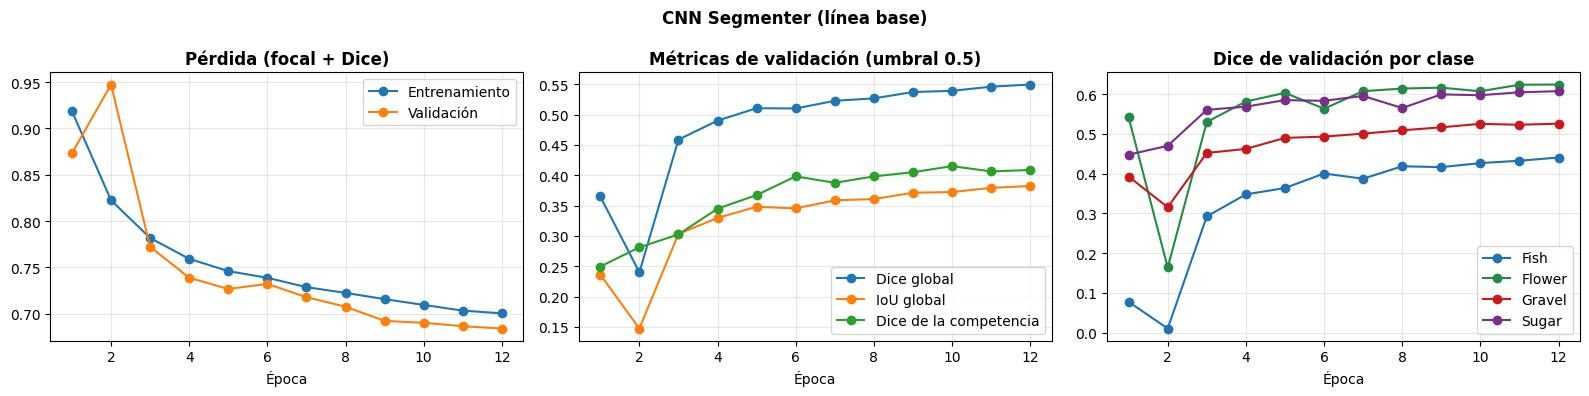

Mejor época: 12 con dice de validación 0.5495


In [8]:
fig = graficas.curvas(historial, "CNN Segmenter (línea base)")
fig.savefig(CARPETA / "curvas.png", dpi=110, bbox_inches="tight")
plt.show()

mejor_fila = historial.loc[historial[METRICA_PRINCIPAL].idxmax()]
print(f"Mejor época: {int(mejor_fila['epoca'])} con {METRICA_PRINCIPAL} de validación {mejor_fila[METRICA_PRINCIPAL]:.4f}")

## 7. Calibración del posprocesado en validación
Se recargan los pesos fp16 guardados, para evaluar exactamente el modelo que usará la app. Sobre validación se comparan tres variantes de posprocesado.

- **A. Umbral 0.5.** Un píxel es de la clase si su probabilidad supera 0.5.
- **B. Umbral por clase.** Se elige el umbral de cada clase que maximiza la métrica principal.
- **C. Umbral + área mínima + morfología.** Además del umbral, se prueba un cierre y una apertura morfológica (rellenar huecos y borrar regiones pequeñas) y un área mínima por debajo de la cual la máscara se borra completa.

Los parámetros se eligen solo con validación y se aplican sin cambios en prueba.

In [9]:
modelo = arquitectura.construir_modelo(preentrenado=False)
meta = cargar_pesos(modelo, MODELO, device)
print(f"Pesos fp16 cargados (época {meta['epoca']})")

probs_val, targets_val, _ = predecir(modelo, "val", device)
config_post = calibrar(probs_val, targets_val)
display(pd.DataFrame(config_post).T)

cnt_val, tabla_val = evaluar_variantes(probs_val, targets_val, config_post)
del probs_val, targets_val
print("Validación (promedio de las 4 clases):")
tabla_val.round(4)

Pesos fp16 cargados (época 12)


,solo_umbral,umbral,area_min,morfologia,metrica_validacion
Fish,0.45,0.45,0.06,False,0.4494
Flower,0.5,0.5,0.06,False,0.628
Gravel,0.5,0.5,0.06,False,0.5279
Sugar,0.5,0.5,0.01,False,0.6076


Validación (promedio de las 4 clases):


,dice,iou,dice_kaggle,precision_pixel,recall_pixel,precision_imagen,recall_imagen,dice_Fish,dice_Flower,dice_Gravel,dice_Sugar
variante,,,,,,,,,,,
A. Umbral 0.5,0.5495,0.3822,0.4086,0.5122,0.5930,0.6024,0.9747,0.4405,0.6241,0.5258,0.6075
B. Umbral por clase,0.5509,0.3834,0.4110,0.5015,0.6136,0.6014,0.9747,0.4461,0.6241,0.5258,0.6075
C. Umbral + área mínima + morfología,0.5532,0.3856,0.5171,0.5074,0.6104,0.6711,0.8951,0.4494,0.6280,0.5279,0.6076


## 8. Evaluación en prueba
Las 555 imágenes de prueba no participaron en ninguna decisión (época, umbral ni posprocesado). Este es el resultado que se reporta.

In [10]:
probs_test, targets_test, ms_lote = predecir(modelo, "test", device)
cnt_test, tabla_test = evaluar_variantes(probs_test, targets_test, config_post)
print("Prueba (promedio de las 4 clases):")
display(tabla_test.round(4))
print("Prueba por clase con el posprocesado completo (variante C):")
tabla(cnt_test["C"]).round(4)

Prueba (promedio de las 4 clases):


,dice,iou,dice_kaggle,precision_pixel,recall_pixel,precision_imagen,recall_imagen,dice_Fish,dice_Flower,dice_Gravel,dice_Sugar
variante,,,,,,,,,,,
A. Umbral 0.5,0.5608,0.3946,0.4226,0.5325,0.5926,0.6064,0.9661,0.4387,0.6674,0.5259,0.6111
B. Umbral por clase,0.5624,0.3960,0.4213,0.5219,0.6112,0.6039,0.9679,0.4451,0.6674,0.5259,0.6111
C. Umbral + área mínima + morfología,0.5652,0.3987,0.5444,0.5286,0.6086,0.6973,0.9056,0.4490,0.6721,0.5286,0.6111


Prueba por clase con el posprocesado completo (variante C):


,Fish,Flower,Gravel,Sugar,Promedio
dice,0.4490,0.6721,0.5286,0.6111,0.5652
iou,0.2895,0.5061,0.3593,0.4400,0.3987
dice_kaggle,0.4210,0.7222,0.5225,0.5121,0.5444
precision_pixel,0.3961,0.6403,0.4989,0.5789,0.5286
recall_pixel,0.5183,0.7072,0.5620,0.6470,0.6086
precision_imagen,0.5950,0.7509,0.6866,0.7565,0.6973
recall_imagen,0.9427,0.8866,0.8601,0.9330,0.9056


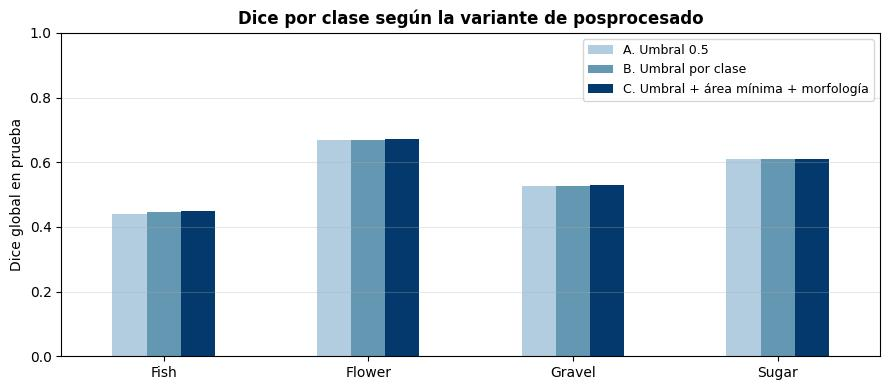

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
por_clase = tabla_test[[f"dice_{l}" for l in LABELS]].T
por_clase.index = LABELS
por_clase.plot.bar(ax=ax, rot=0, color=["#b3cde0", "#6497b1", "#03396c"])
ax.set_ylabel("Dice global en prueba")
ax.set_ylim(0, 1)
ax.set_title("Dice por clase según la variante de posprocesado", fontweight="bold")
ax.grid(axis="y", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(CARPETA / "dice_por_clase.png", dpi=110)
plt.show()

## 9. Visualización de predicciones
Las tres imágenes de prueba con mejor Dice y las tres con peor, con el posprocesado completo. Después, los mapas de probabilidad de una imagen típica (la de Dice mediano), con el contorno de la etiqueta en blanco.

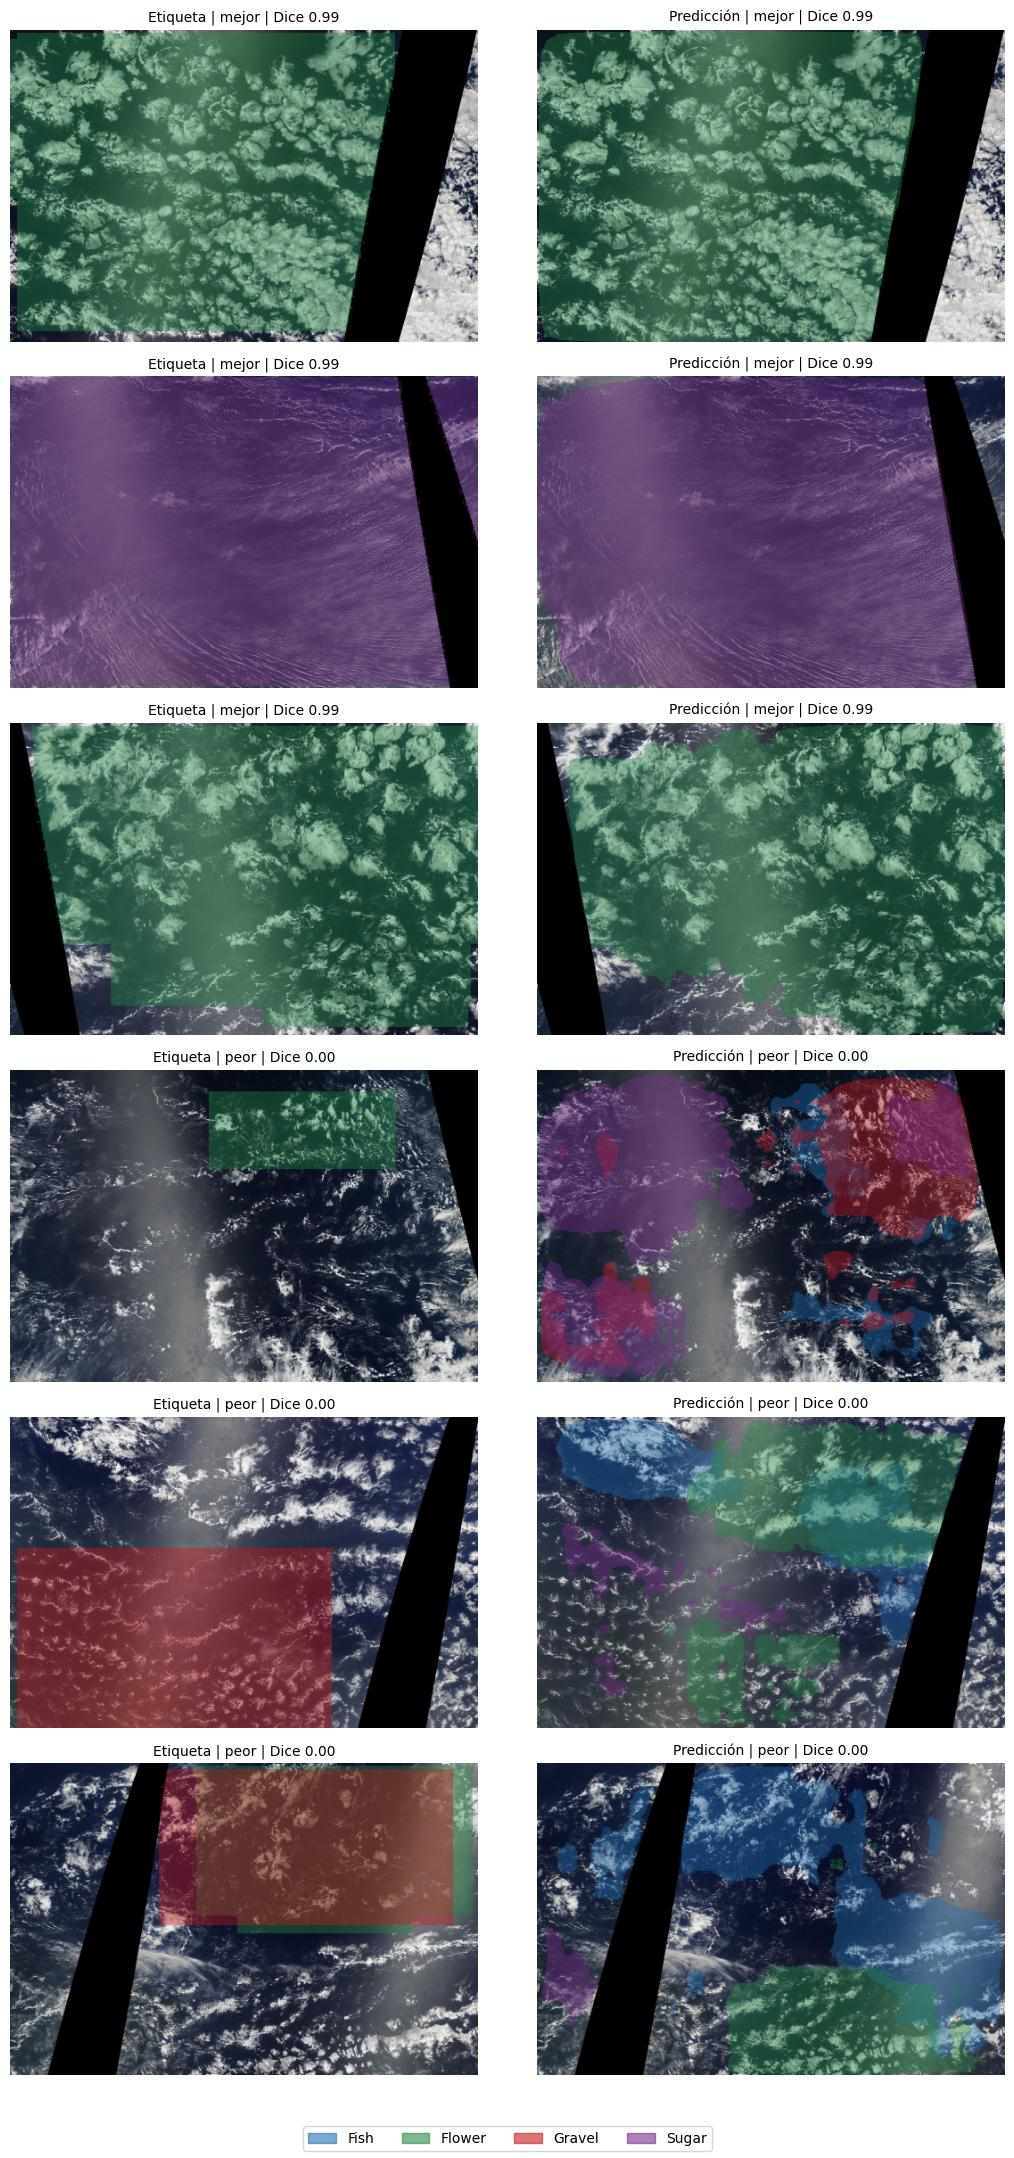

In [12]:
test_ds = CloudDataset("test")
pred_test = aplicar(probs_test, config_post, "C")
dice_img = dice_por_imagen(cnt_test["C"])
orden = np.argsort(dice_img)
elegidos = list(orden[-3:][::-1]) + list(orden[:3])
imagenes = [test_ds.imagen_y_mascara(i)[0][:IN_H, :IN_W] for i in elegidos]
fig = graficas.ejemplos(imagenes, targets_test[elegidos], pred_test[elegidos], dice_img[elegidos],
                        ["mejor"] * 3 + ["peor"] * 3)
fig.savefig(CARPETA / "ejemplos.jpg", dpi=110, pil_kwargs={"quality": 85})
plt.show()

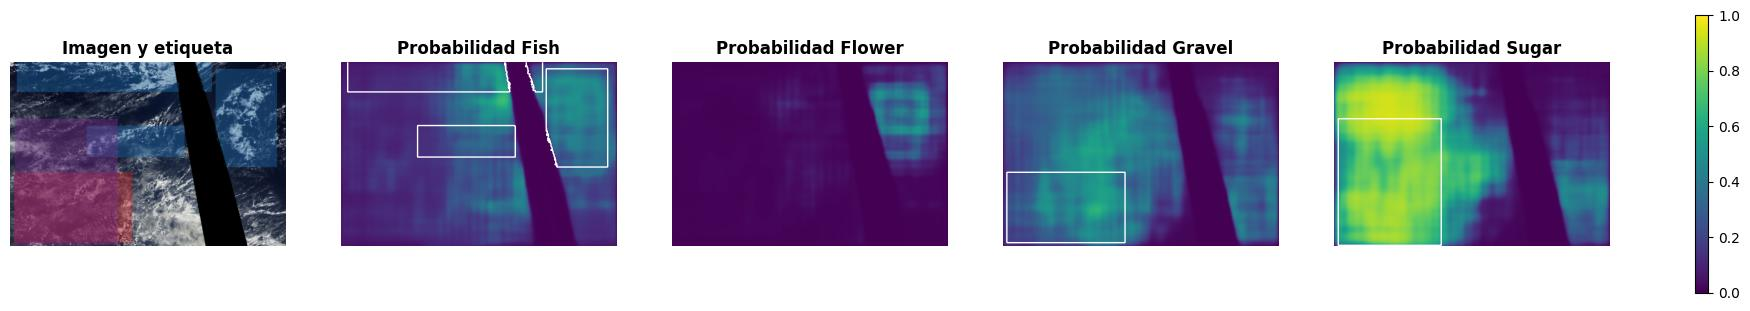

In [13]:
i = int(orden[len(orden) // 2])
fig = graficas.mapas_probabilidad(test_ds.imagen_y_mascara(i)[0][:IN_H, :IN_W], probs_test[i], targets_test[i])
fig.savefig(CARPETA / "mapas_probabilidad.jpg", dpi=110, bbox_inches="tight", pil_kwargs={"quality": 85})
plt.show()

## 10. Guardado de artefactos
Todo queda en `artifacts/<modelo>/`, para comparar modelos y desplegar el campeón sin volver a entrenar.

| Archivo | Contenido |
|---|---|
| `pesos_fp16.pt` | Pesos de la mejor época en media precisión |
| `historial.csv` | Pérdida y métricas por época |
| `posproceso.json` | Umbral, área mínima y morfología por clase |
| `metricas.csv` | Todas las métricas por partición, variante y clase |
| `conteos.npz` | Intersección y áreas por imagen y clase, para el bootstrap del notebook del campeón |
| `resumen.json` | Cifras principales del modelo |
| `resultados.pkl` | Todo lo anterior (salvo los pesos) en un solo objeto de Python |
| `*.png`, `*.jpg` | Curvas, Dice por clase, ejemplos y mapas de probabilidad |

In [14]:
info = {
    "n_params": n_params,
    "mejor_epoca": int(mejor_fila["epoca"]),
    "ms_por_imagen_evaluacion": round(ms_lote, 2),
    "dispositivo_evaluacion": torch.cuda.get_device_name(0) if device.type == "cuda" else "cpu",
    "ms_por_imagen_cpu": round(tiempo_cpu_ms(modelo), 1),
}
resumen = guardar_resultados(MODELO, historial, config_post, cnt_val, cnt_test, tabla_val, tabla_test, info)
resumen

Artefactos guardados en /kaggle/working/repo/artifacts/cnn:
  conteos.npz                0.09 MB
  curvas.png                 0.13 MB
  dice_por_clase.png         0.03 MB
  ejemplos.jpg               0.57 MB
  historial.csv              0.00 MB
  mapas_probabilidad.jpg     0.07 MB
  metricas.csv               0.00 MB
  pesos_fp16.pt             14.01 MB
  posproceso.json            0.00 MB
  resultados.pkl             0.33 MB
  resumen.json               0.00 MB


{'modelo': 'cnn',
 'nombre': 'CNN Segmenter',
 'fecha': '2026-11-18 04:47',
 'metrica_principal': 'dice',
 'validacion': {'A': 0.5495, 'B': 0.5509, 'C': 0.5532},
 'prueba': {'A': 0.5608, 'B': 0.5624, 'C': 0.5652},
 'n_params': 6979780,
 'mejor_epoca': 12,
 'ms_por_imagen_evaluacion': 8.96,
 'dispositivo_evaluacion': 'Tesla T4',
 'ms_por_imagen_cpu': 816.5}

## 11. Resumen

In [15]:
print(f"{resumen['nombre']} ({n_params / 1e6:.1f} M parámetros, mejor época {resumen['mejor_epoca']})")
for v, nombre in [("A", "umbral 0.5"), ("B", "umbral por clase"), ("C", "posprocesado completo")]:
    print(f"  {METRICA_PRINCIPAL} con {nombre:22s} validación {resumen['validacion'][v]:.4f} | prueba {resumen['prueba'][v]:.4f}")
print(f"  Inferencia en CPU: {resumen['ms_por_imagen_cpu']:.0f} ms por imagen")
print("La comparación entre modelos y la elección del campeón están en 05_champion.ipynb")

CNN Segmenter (7.0 M parámetros, mejor época 12)
  dice con umbral 0.5             validación 0.5495 | prueba 0.5608
  dice con umbral por clase       validación 0.5509 | prueba 0.5624
  dice con posprocesado completo  validación 0.5532 | prueba 0.5652
  Inferencia en CPU: 816 ms por imagen
La comparación entre modelos y la elección del campeón están en 05_champion.ipynb
